# Visualisasi Data dengan Matplotlib & Seaborn
## Analisis Penjualan Mobil XYZAutomotives pada Periode Resesi dan Non-Resesi

Dataset: `historical_automobile_sales.csv` (penjualan bulanan, 1980 dan seterusnya).

| Kolom | Keterangan |
|---|---|
| Year, Month, Date | Waktu pengamatan |
| Recession | 1 = periode resesi, 0 = non-resesi |
| Automobile_Sales | Rata-rata penjualan mobil bulanan |
| Advertising_Expenditure | Pengeluaran iklan XYZAutomotives |
| Vehicle_Type | Jenis kendaraan |
| Price | Harga rata-rata kendaraan |
| GDP | Produk Domestik Bruto |
| unemployment_rate | Tingkat pengangguran |
| Seasonality_Weight | Bobot musiman |
| Consumer_Confidence | Indeks kepercayaan konsumen |

## 0. Import library dan muat data

In [13]:
import numpy as np
%pip install pandas
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_theme(style="whitegrid")

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/historical_automobile_sales.csv"
df = pd.read_csv(URL)

# Rapikan nama kolom (beberapa versi dataset menulis Unemployment_Rate dengan huruf besar)
df.columns = df.columns.str.strip()
df = df.rename(columns={c: "unemployment_rate" for c in df.columns if c.lower() == "unemployment_rate"})

print("Dimensi data:", df.shape)
df.head()

Dimensi data: (528, 15)


,Date,Year,Month,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales,Vehicle_Type,City
0,1/31/1980,1980,Jan,1,108.24,0.50,27483.571,1558,7,60.223,0.010000,5.4,456.0,Supperminicar,Georgia
1,2/29/1980,1980,Feb,1,98.75,0.75,24308.678,3048,4,45.986,-0.309594,4.8,555.9,Supperminicar,New York
2,3/31/1980,1980,Mar,1,107.48,0.20,28238.443,3137,3,35.141,-0.308614,3.4,620.0,Mediumfamilycar,New York
3,4/30/1980,1980,Apr,1,115.01,1.00,32615.149,1653,7,45.673,0.230596,4.2,702.8,Supperminicar,Illinois
4,5/31/1980,1980,May,1,98.72,0.20,23829.233,1319,4,52.997,0.138197,5.3,770.4,Smallfamiliycar,California


In [14]:
print("Nilai kosong per kolom:")
print(df.isnull().sum())
print()
print("Jumlah baris per periode:")
print(df["Recession"].map({0: "Non-recession", 1: "Recession"}).value_counts())
print()
print("Jenis kendaraan:", df["Vehicle_Type"].unique())

Nilai kosong per kolom:
Date                       0
Year                       0
Month                      0
Recession                  0
Consumer_Confidence        0
Seasonality_Weight         0
Price                      0
Advertising_Expenditure    0
Competition                0
GDP                        0
Growth_Rate                0
unemployment_rate          0
Automobile_Sales           0
Vehicle_Type               0
City                       0
dtype: int64

Jumlah baris per periode:
Recession
Non-recession    415
Recession        113
Name: count, dtype: int64

Jenis kendaraan: ['Supperminicar' 'Mediumfamilycar' 'Smallfamiliycar' 'Sports'
 'Executivecar']


## 1.1 Grafik garis: fluktuasi penjualan mobil dari tahun ke tahun
Rata-rata penjualan per tahun. Tahun yang memiliki bulan resesi diberi blok merah.

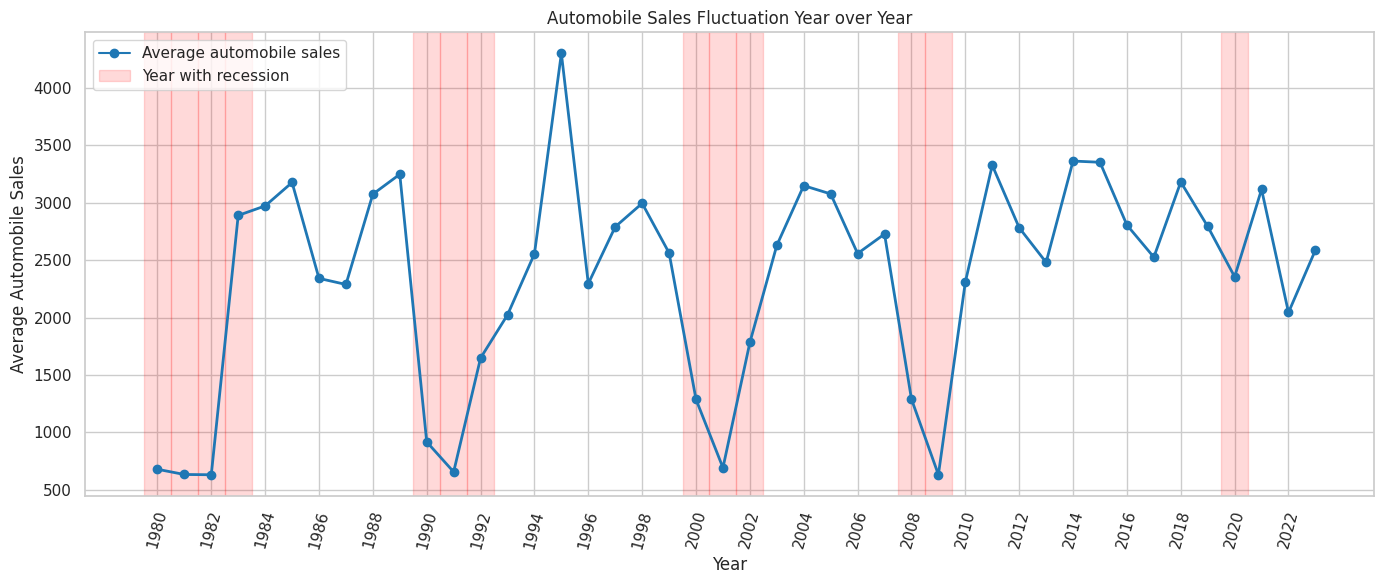

Tahun penjualan tertinggi : 1995 (4300.2)
Tahun penjualan terendah  : 1982 (631.1)


In [15]:
yearly_sales = df.groupby("Year")["Automobile_Sales"].mean()
recession_years = sorted(df.loc[df["Recession"] == 1, "Year"].unique())

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(yearly_sales.index, yearly_sales.values, marker="o", linewidth=2, color="tab:blue")
for y in recession_years:
    ax.axvspan(y - 0.5, y + 0.5, color="red", alpha=0.15)

ax.set_xticks(np.arange(df["Year"].min(), df["Year"].max() + 1, 2))
ax.tick_params(axis="x", rotation=75)
ax.set_xlabel("Year")
ax.set_ylabel("Average Automobile Sales")
ax.set_title("Automobile Sales Fluctuation Year over Year")
ax.legend(handles=[
    plt.Line2D([0], [0], color="tab:blue", marker="o", label="Average automobile sales"),
    mpatches.Patch(color="red", alpha=0.15, label="Year with recession"),
], loc="upper left")
plt.tight_layout()
plt.show()

print(f"Tahun penjualan tertinggi : {yearly_sales.idxmax()} ({yearly_sales.max():.1f})")
print(f"Tahun penjualan terendah  : {yearly_sales.idxmin()} ({yearly_sales.min():.1f})")

## 1.2 Grafik garis: pengeluaran iklan vs penjualan mobil (periode non-resesi)
Dua sumbu-y dipakai karena skala kedua variabel berbeda.

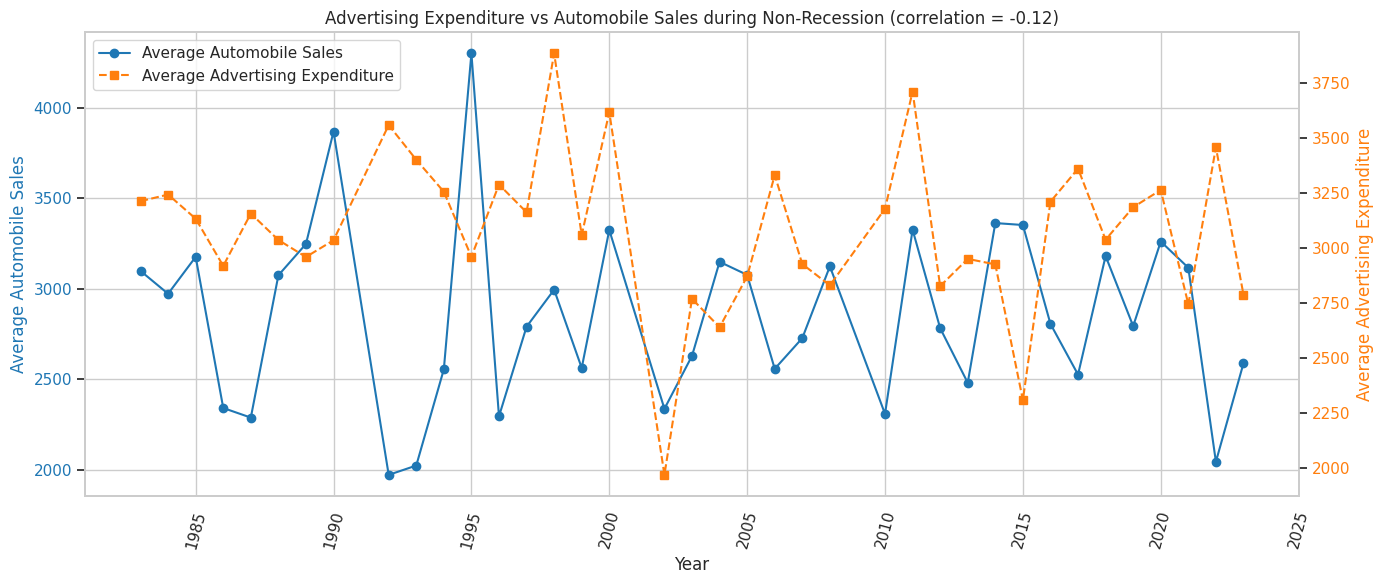

Korelasi pengeluaran iklan dan penjualan (non-resesi): -0.124


In [16]:
non_rec = df[df["Recession"] == 0]
ad_sales = non_rec.groupby("Year")[["Advertising_Expenditure", "Automobile_Sales"]].mean()
corr_ad = ad_sales["Advertising_Expenditure"].corr(ad_sales["Automobile_Sales"])

fig, ax1 = plt.subplots(figsize=(14, 6))
l1 = ax1.plot(ad_sales.index, ad_sales["Automobile_Sales"], marker="o",
              color="tab:blue", label="Average Automobile Sales")
ax1.set_xlabel("Year")
ax1.set_ylabel("Average Automobile Sales", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.tick_params(axis="x", rotation=75)

ax2 = ax1.twinx()
l2 = ax2.plot(ad_sales.index, ad_sales["Advertising_Expenditure"], marker="s", linestyle="--",
              color="tab:orange", label="Average Advertising Expenditure")
ax2.set_ylabel("Average Advertising Expenditure", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")
ax2.grid(False)

lines = l1 + l2
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left")
ax1.set_title(f"Advertising Expenditure vs Automobile Sales during Non-Recession (correlation = {corr_ad:.2f})")
plt.tight_layout()
plt.show()

print(f"Korelasi pengeluaran iklan dan penjualan (non-resesi): {corr_ad:.3f}")

## 1.3 Grafik batang: penjualan per jenis kendaraan, resesi vs non-resesi

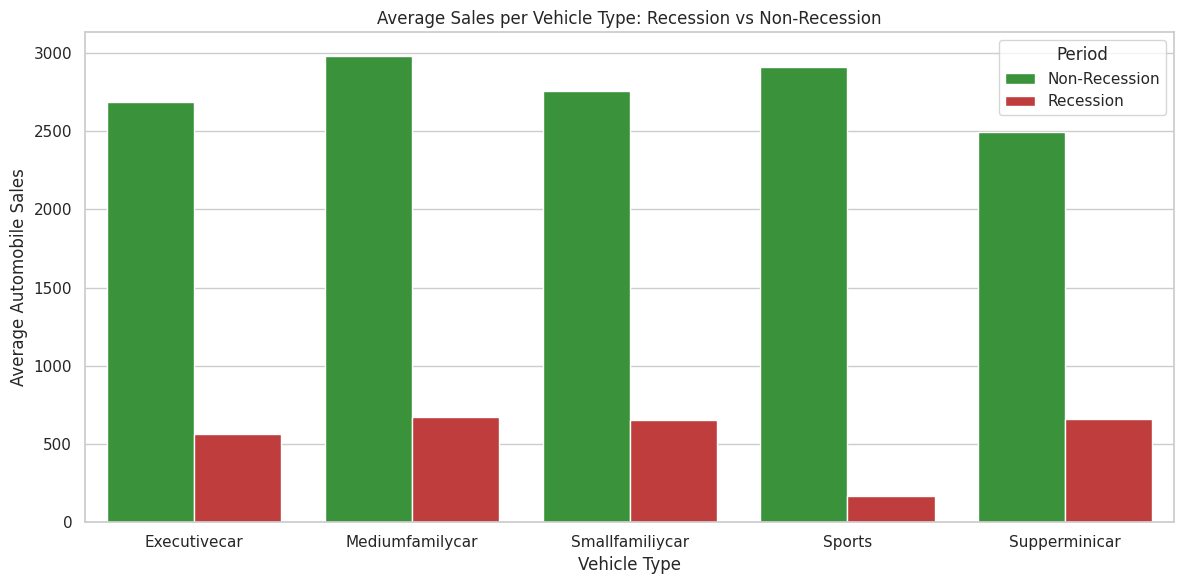

Period,Non-Recession,Recession,Change (%)
Vehicle_Type,,,
Executivecar,2686.44,564.00,-79.01
Mediumfamilycar,2981.50,674.85,-77.37
Smallfamiliycar,2752.66,650.73,-76.36
Sports,2910.64,170.33,-94.15
Supperminicar,2495.24,659.27,-73.58


In [17]:
vt = (df.groupby(["Recession", "Vehicle_Type"])["Automobile_Sales"].mean().reset_index())
vt["Period"] = vt["Recession"].map({1: "Recession", 0: "Non-Recession"})

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=vt, x="Vehicle_Type", y="Automobile_Sales", hue="Period",
            palette={"Recession": "tab:red", "Non-Recession": "tab:green"}, ax=ax)
ax.set_xlabel("Vehicle Type")
ax.set_ylabel("Average Automobile Sales")
ax.set_title("Average Sales per Vehicle Type: Recession vs Non-Recession")
plt.tight_layout()
plt.show()

pivot = vt.pivot(index="Vehicle_Type", columns="Period", values="Automobile_Sales")
pivot["Change (%)"] = (pivot["Recession"] - pivot["Non-Recession"]) / pivot["Non-Recession"] * 100
pivot.round(2)

## 1.4 Subplot: variasi GDP pada periode resesi dan non-resesi

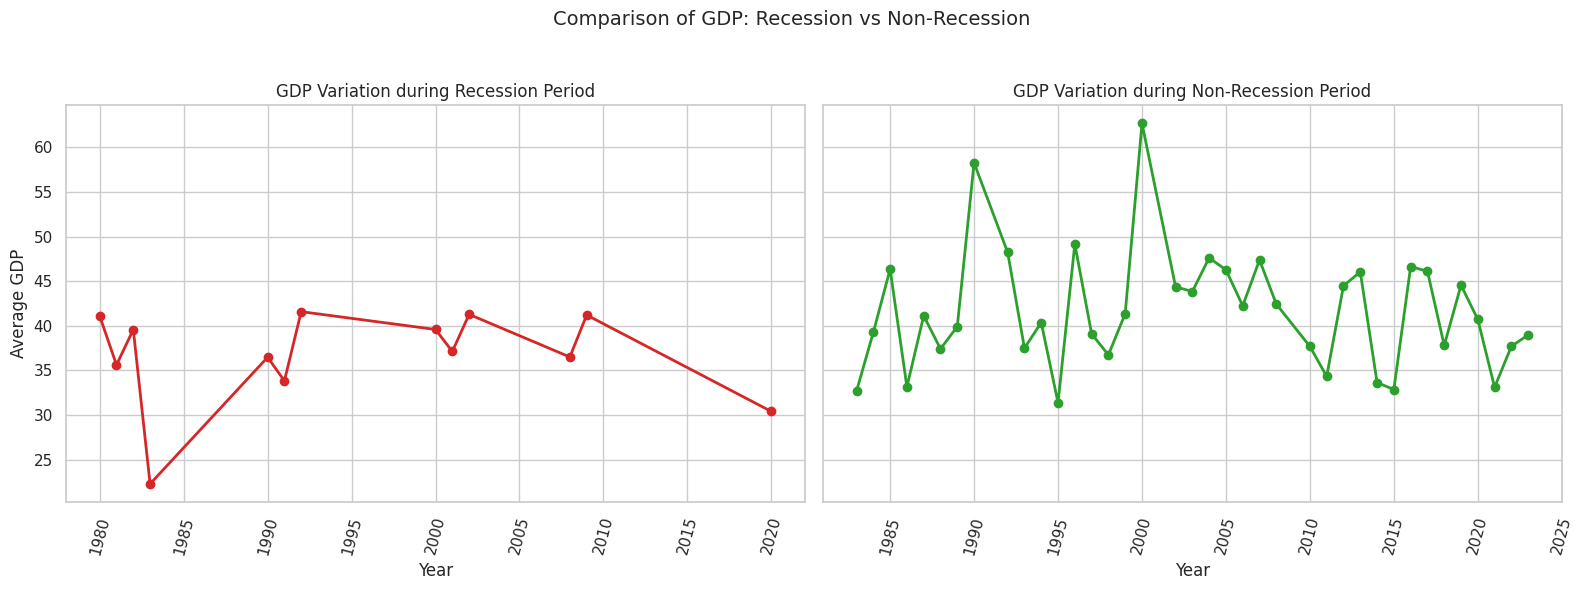

In [18]:
gdp = df.groupby(["Recession", "Year"])["GDP"].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
settings = [(1, "Recession", "tab:red"), (0, "Non-Recession", "tab:green")]

for ax, (flag, label, color) in zip(axes, settings):
    sub = gdp[gdp["Recession"] == flag]
    ax.plot(sub["Year"], sub["GDP"], marker="o", color=color, linewidth=2)
    ax.set_title(f"GDP Variation during {label} Period")
    ax.set_xlabel("Year")
    ax.tick_params(axis="x", rotation=75)

axes[0].set_ylabel("Average GDP")
fig.suptitle("Comparison of GDP: Recession vs Non-Recession", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 1.5 Grafik gelembung: dampak musiman pada penjualan mobil
Sumbu-x = bulan, sumbu-y = rata-rata penjualan, ukuran dan warna gelembung = rata-rata `Seasonality_Weight`.

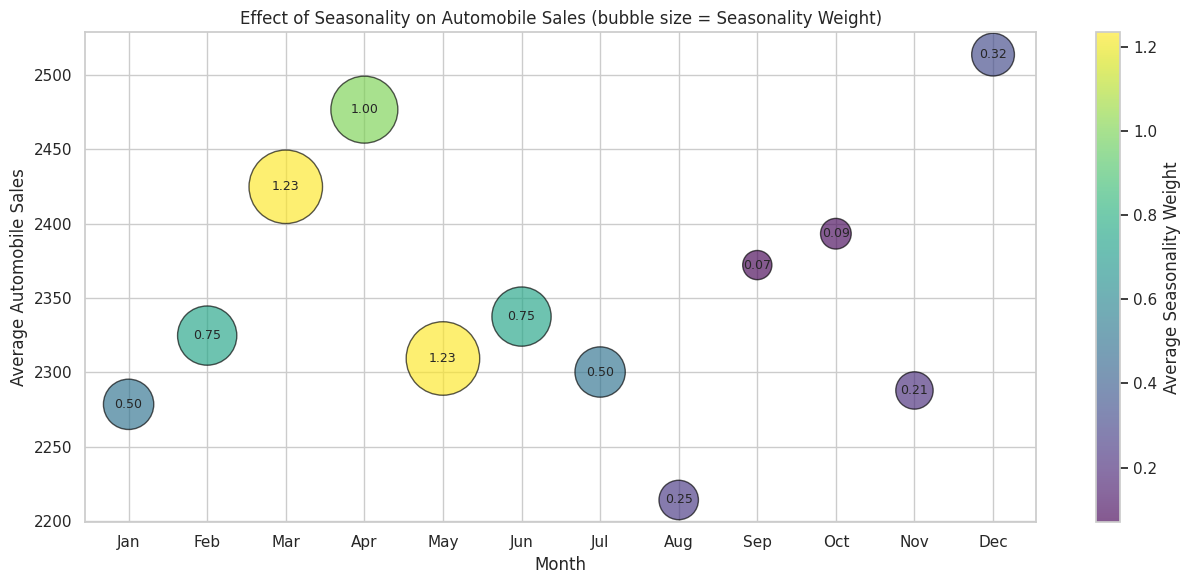

In [19]:
month_order = df["Month"].drop_duplicates().tolist()   # urutan kemunculan = urutan kalender
seasonal = (df.groupby("Month")
              .agg(Sales=("Automobile_Sales", "mean"), Seasonality=("Seasonality_Weight", "mean"))
              .reindex(month_order)
              .reset_index())

max_w = seasonal["Seasonality"].max() or 1
sizes = 300 + 2500 * seasonal["Seasonality"] / max_w

fig, ax = plt.subplots(figsize=(13, 6))
sc = ax.scatter(seasonal["Month"], seasonal["Sales"], s=sizes, c=seasonal["Seasonality"],
                cmap="viridis", alpha=0.65, edgecolors="black")
for _, row in seasonal.iterrows():
    ax.annotate(f"{row['Seasonality']:.2f}", (row["Month"], row["Sales"]),
                ha="center", va="center", fontsize=9)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Average Seasonality Weight")
ax.set_xlabel("Month")
ax.set_ylabel("Average Automobile Sales")
ax.set_title("Effect of Seasonality on Automobile Sales (bubble size = Seasonality Weight)")
plt.tight_layout()
plt.show()

## 1.6 Grafik sebar: harga rata-rata kendaraan vs volume penjualan saat resesi

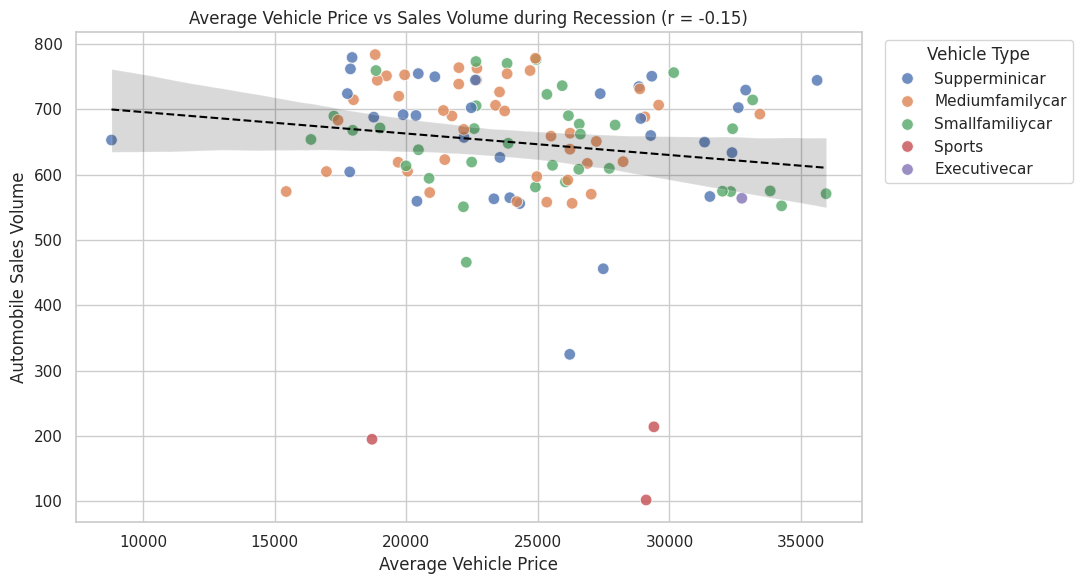

Korelasi harga vs penjualan (resesi): -0.147


In [20]:
rec = df[df["Recession"] == 1]
corr_price = rec["Price"].corr(rec["Automobile_Sales"])

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=rec, x="Price", y="Automobile_Sales", hue="Vehicle_Type",
                s=70, alpha=0.8, ax=ax)
sns.regplot(data=rec, x="Price", y="Automobile_Sales", scatter=False,
            color="black", line_kws={"linestyle": "--", "linewidth": 1.5}, ax=ax)
ax.set_xlabel("Average Vehicle Price")
ax.set_ylabel("Automobile Sales Volume")
ax.set_title(f"Average Vehicle Price vs Sales Volume during Recession (r = {corr_price:.2f})")
ax.legend(title="Vehicle Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"Korelasi harga vs penjualan (resesi): {corr_price:.3f}")

## 1.7 Grafik pai: porsi pengeluaran iklan resesi vs non-resesi

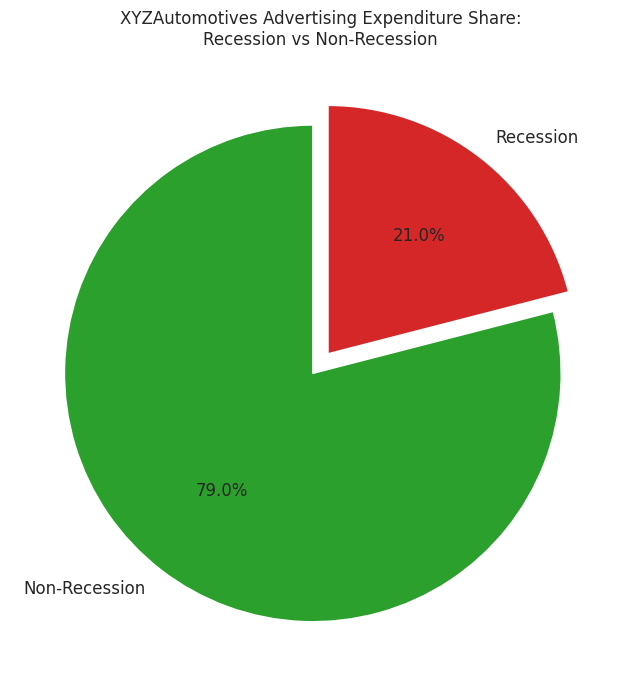

Recession
Non-Recession    1279707
Recession         339910
Name: Advertising_Expenditure, dtype: int64


In [21]:
ad_share = (df.groupby("Recession")["Advertising_Expenditure"].sum()
              .rename(index={0: "Non-Recession", 1: "Recession"}))

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(ad_share.values, labels=ad_share.index, autopct="%1.1f%%", startangle=90,
       colors=["tab:green" if i == "Non-Recession" else "tab:red" for i in ad_share.index],
       explode=[0.05] * len(ad_share), textprops={"fontsize": 12})
ax.set_title("XYZAutomotives Advertising Expenditure Share:\nRecession vs Non-Recession")
plt.tight_layout()
plt.show()

print(ad_share.round(0))

## 1.8 Grafik pai: total pengeluaran iklan per jenis kendaraan saat resesi

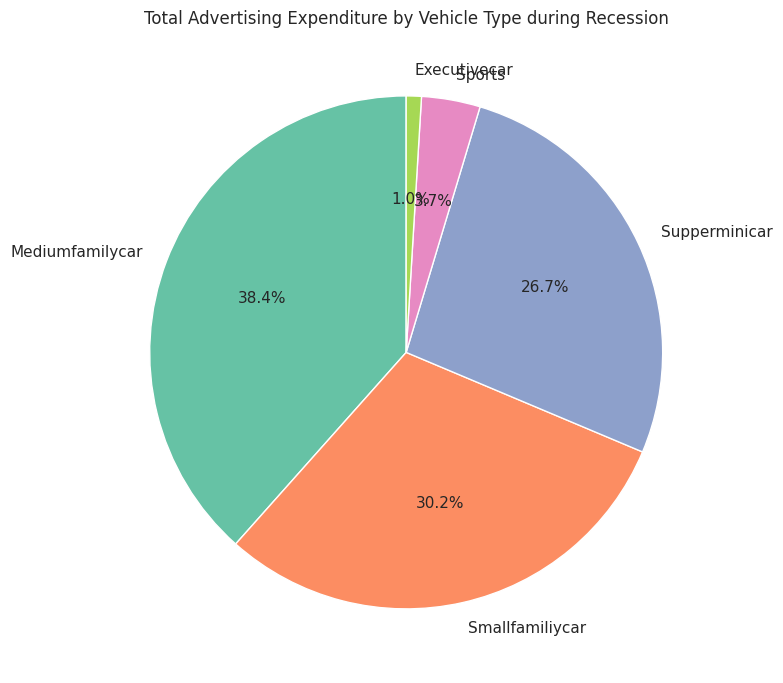

Vehicle_Type
Mediumfamilycar    130612
Smallfamiliycar    102759
Supperminicar       90728
Sports              12568
Executivecar         3243
Name: Advertising_Expenditure, dtype: int64


In [22]:
rec_ad = (df[df["Recession"] == 1]
            .groupby("Vehicle_Type")["Advertising_Expenditure"].sum()
            .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(rec_ad.values, labels=rec_ad.index, autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("Set2", len(rec_ad)), textprops={"fontsize": 11})
ax.set_title("Total Advertising Expenditure by Vehicle Type during Recession")
plt.tight_layout()
plt.show()

print(rec_ad.round(0))

## 1.9 Grafik garis: pengaruh tingkat pengangguran terhadap jenis kendaraan dan penjualan (resesi)

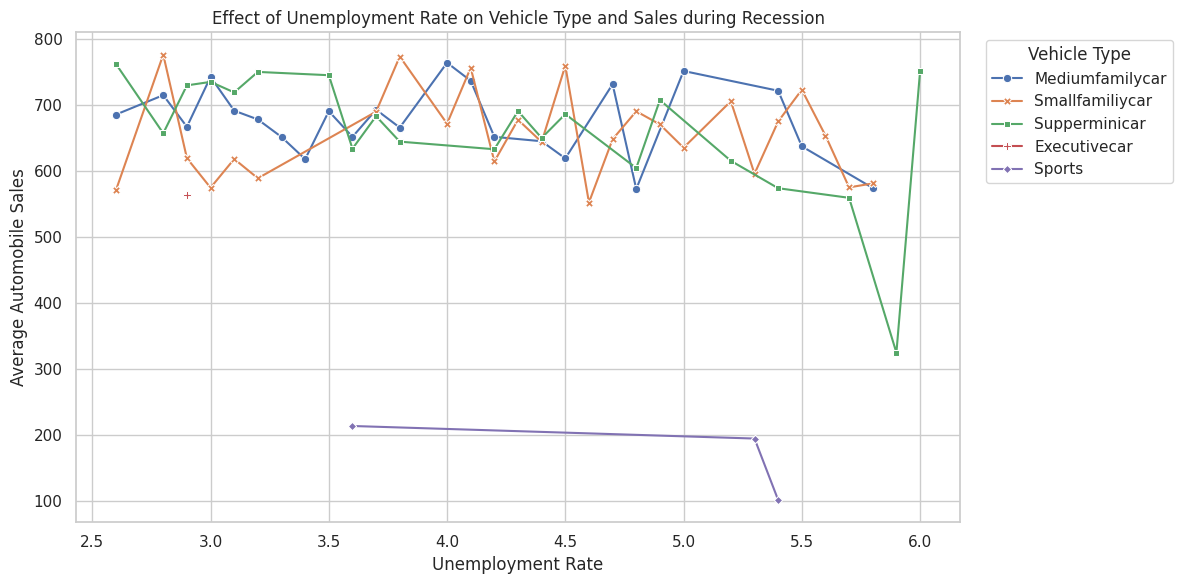

In [23]:
rec = df[df["Recession"] == 1]
unemp = (rec.groupby(["unemployment_rate", "Vehicle_Type"])["Automobile_Sales"]
            .mean().reset_index())

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=unemp, x="unemployment_rate", y="Automobile_Sales",
             hue="Vehicle_Type", style="Vehicle_Type", markers=True, dashes=False, ax=ax)
ax.set_xlabel("Unemployment Rate")
ax.set_ylabel("Average Automobile Sales")
ax.set_title("Effect of Unemployment Rate on Vehicle Type and Sales during Recession")
ax.legend(title="Vehicle Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Catatan akhir
Jalankan **Kernel > Restart & Run All** sebelum menyimpan, supaya semua grafik tersimpan di dalam notebook yang diunggah.